# Bias vs variance with trees — the figure in section 1 of the README

This notebook builds `../images/bias_variance_trees.png`, the three-panel picture used in
[`../README.md`](../README.md) (sections 1 and 3).

**The experiment.** Pretend we can collect many training sets from the same source. We draw
15 of them, each with 60 noisy points from the same pattern, and train the same kind of model on
each one. Then we plot all 15 fitted models on top of each other:

* if the 15 lines sit **in the wrong place** together → **bias**;
* if the 15 lines are **spread out** → **variance**.

Three kinds of model are compared: a stump (depth-1 tree), a fully grown tree, and the average of
100 fully grown trees trained on bootstrap samples (bagging).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

SEED = 0
N_POINTS = 60          # rows in each training set
NOISE_SD = 0.4        # standard deviation of the Gaussian noise added to y
N_TRAINING_SETS = 15  # how many independent training sets (= blue lines per panel)
N_BAGGED_TREES = 100  # trees averaged inside the bagging model
X_MIN, X_MAX = 0.0, 5.0

OUTPUT_PATH = Path("../images/bias_variance_trees.png")

## 1. The source of the data

The true pattern is $f(x) = \sin(2x) + 0.3x$: a wave on a gentle upward trend. A training set is
60 values of $x$ drawn uniformly from $[0, 5]$, with $y = f(x) + \varepsilon$ and
$\varepsilon \sim \mathcal{N}(0, 0.4^2)$.

In [2]:
def true_pattern(x):
    return np.sin(2 * x) + 0.3 * x


def draw_training_set(rng):
    x = rng.uniform(X_MIN, X_MAX, N_POINTS)
    y = true_pattern(x) + rng.normal(0, NOISE_SD, N_POINTS)
    return x.reshape(-1, 1), y


rng = np.random.default_rng(SEED)
training_sets = [draw_training_set(rng) for _ in range(N_TRAINING_SETS)]

x_grid = np.linspace(X_MIN, X_MAX, 500)
truth = true_pattern(x_grid)
print(f"{len(training_sets)} training sets of {N_POINTS} points each")

15 training sets of 60 points each


## 2. The three models

Each entry makes a fresh, untrained model. `seed` only matters for bagging (which bootstrap rows
each tree sees); it is set per training set so the whole notebook is reproducible.

In [3]:
MODELS = {
    "stump": lambda seed: DecisionTreeRegressor(max_depth=1),
    "deep tree": lambda seed: DecisionTreeRegressor(random_state=seed),
    "bagging": lambda seed: BaggingRegressor(
        DecisionTreeRegressor(), n_estimators=N_BAGGED_TREES, random_state=seed
    ),
}

PANEL_TITLES = {
    "stump": "stump (depth 1): HIGH bias, low variance",
    "deep tree": "deep tree: low bias, HIGH variance",
    "bagging": f"average of {N_BAGGED_TREES} deep trees (bagging):\nlow bias, lower variance",
}

## 3. Train every model on every training set

`predictions[name]` has shape `(15, 500)`: one row per training set, one column per point of the
plotting grid.

In [4]:
def predict_on_grid(make_model, training_sets, grid):
    return np.array([
        make_model(seed).fit(X, y).predict(grid.reshape(-1, 1))
        for seed, (X, y) in enumerate(training_sets)
    ])


predictions = {name: predict_on_grid(make, training_sets, x_grid) for name, make in MODELS.items()}
{name: preds.shape for name, preds in predictions.items()}

{'stump': (15, 500), 'deep tree': (15, 500), 'bagging': (15, 500)}

## 4. The numbers behind the picture

Using the decomposition from section 3 of the README, averaged over the grid:

* **bias²** = squared distance between the *average* of the 15 fits and the true pattern;
* **variance** = spread of the 15 fits around their own average.

With only 15 training sets these are rough estimates, but the ordering is what the figure shows.

In [5]:
def bias_squared_and_variance(preds):
    average_fit = preds.mean(axis=0)
    bias_squared = np.mean((average_fit - truth) ** 2)
    variance = np.mean(preds.var(axis=0))
    return bias_squared, variance


print(f"{'model':<10} {'bias^2':>8} {'variance':>9}")
for name, preds in predictions.items():
    bias_squared, variance = bias_squared_and_variance(preds)
    print(f"{name:<10} {bias_squared:>8.3f} {variance:>9.3f}")

model        bias^2  variance
stump         0.216     0.027
deep tree     0.009     0.161
bagging       0.005     0.078


## 5. Draw and save the figure

Blue: the 15 individual fits. Orange: their average. Black dashed: the true pattern.

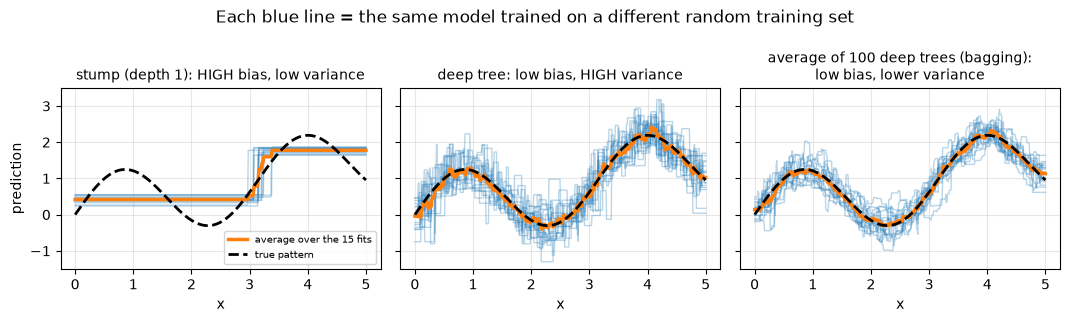

saved ../images/bias_variance_trees.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.24), sharey=True)

for ax, (name, preds) in zip(axes, predictions.items()):
    for single_fit in preds:
        ax.plot(x_grid, single_fit, color="tab:blue", alpha=0.3, lw=1)
    ax.plot(x_grid, preds.mean(axis=0), color="tab:orange", lw=2.5,
            label=f"average over the {N_TRAINING_SETS} fits")
    ax.plot(x_grid, truth, "k--", lw=2, label="true pattern")
    ax.set_title(PANEL_TITLES[name], fontsize=10)
    ax.set_xlabel("x")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("prediction")
axes[0].set_ylim(-1.5, 3.5)
axes[0].legend(loc="lower right", fontsize=7)
fig.suptitle("Each blue line = the same model trained on a different random training set")
fig.tight_layout()

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_PATH, dpi=100)
plt.show()
print(f"saved {OUTPUT_PATH}")

## 6. What to read off the figure

* **Stump.** The 15 lines nearly coincide (low variance) but every one is a single step that cannot
  follow the wave (high bias).
* **Deep tree.** The average (orange) follows the wave (low bias), but each fit is jagged and
  different from the others: it memorised its own sample's noise (high variance).
* **Bagging.** The average still follows the wave, and the individual lines are much calmer:
  averaging 100 trees cancelled part of the noise-chasing. Same low bias, lower variance — the idea
  developed in [`../02-bagging/`](../02-bagging/README.md).

## 7. Beyond the training range: no extrapolation

Every training set covered only $x \in [0, 5]$. What do the same models predict a little further out, where
the true pattern keeps waving upwards? We refit them on the **same 15 training sets** and predict on
$[0, 7.5]$. The grey band is the region no model has seen.

A tree answers "which leaf does this point fall in?". Every $x$ above the largest training value lands in
the **last leaf**, so the prediction stops changing there — for a stump, a deep tree, and an average of
100 deep trees alike. This is [disadvantage 4](../README.md#disadvantage-4) in the README.

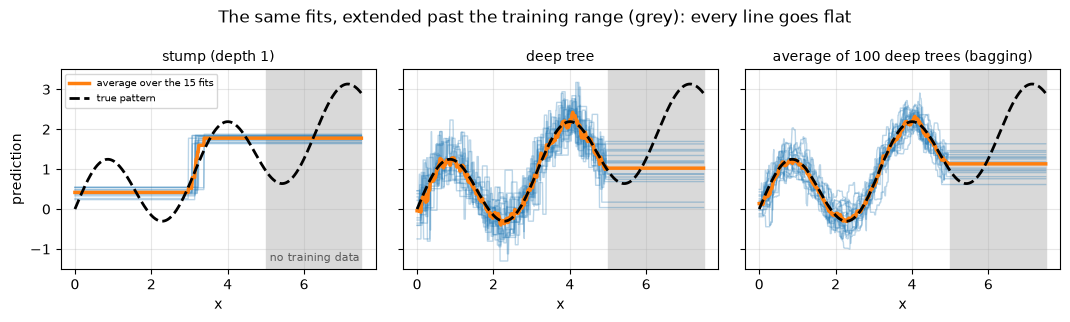

In [7]:
X_EDGE, X_FAR = X_MAX, 7.5
x_wide = np.linspace(X_MIN, X_FAR, 750)
truth_wide = true_pattern(x_wide)
beyond = x_wide > X_EDGE

wide_predictions = {name: predict_on_grid(make, training_sets, x_wide) for name, make in MODELS.items()}

fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.24), sharey=True)
for ax, (name, preds) in zip(axes, wide_predictions.items()):
    ax.axvspan(X_EDGE, X_FAR, color="0.85", zorder=0)
    for single_fit in preds:
        ax.plot(x_wide, single_fit, color="tab:blue", alpha=0.3, lw=1)
    ax.plot(x_wide, preds.mean(axis=0), color="tab:orange", lw=2.5,
            label=f"average over the {N_TRAINING_SETS} fits")
    ax.plot(x_wide, truth_wide, "k--", lw=2, label="true pattern")
    ax.set_title(PANEL_TITLES[name].split(":")[0], fontsize=10)
    ax.set_xlabel("x")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("prediction")
axes[0].set_ylim(-1.5, 3.5)
axes[0].text(X_EDGE + 0.1, -1.3, "no training data", fontsize=8, color="0.35")
axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle("The same fits, extended past the training range (grey): every line goes flat")
fig.tight_layout()
plt.show()

The numbers behind the flat lines. For each model: the average of the 15 fits at $x = 5$ (the edge), $6$
and $7$ against the truth, and the **largest change of any single fit** anywhere past the edge.

In [8]:
def value_at(x_value, curve):
    return np.interp(x_value, x_wide, curve)


print(f"{'model':<10} {'avg@5':>6} {'avg@6':>6} {'avg@7':>6}   {'max change past x=5':>19}")
for name, preds in wide_predictions.items():
    average_fit = preds.mean(axis=0)
    edge_values = preds[:, ~beyond][:, -1:]                 # each fit's value at the last grid point <= 5
    max_change = np.abs(preds[:, beyond] - edge_values).max()
    print(f"{name:<10} {value_at(5, average_fit):6.2f} {value_at(6, average_fit):6.2f} "
          f"{value_at(7, average_fit):6.2f}   {max_change:19.3f}")
print(f"{'truth':<10} {true_pattern(5):6.2f} {true_pattern(6):6.2f} {true_pattern(7):6.2f}")

model       avg@5  avg@6  avg@7   max change past x=5
stump        1.78   1.78   1.78                 0.000
deep tree    1.02   1.02   1.02                 0.000
bagging      1.13   1.13   1.13                 0.000
truth        0.96   1.26   3.09


## 8. What to read off the extrapolation figure

* **Every line goes flat at the edge** — all 15 fits of all three models. The largest change of any fit past
  $x = 5$ is exactly 0: past its last split a tree has nothing left to ask.
* **Bagging does not help.** The average of 100 flat lines is a flat line. Averaging cancels *noise*; it
  cannot invent a shape the members do not have outside the data.
* **Low bias inside the range, growing bias outside it.** The deep tree and the bagged trees follow the wave
  up to $x = 5$ (sections 4–6), but from there the gap to the truth is whatever the wave does next — here the
  gap reaches 2.07 (deep tree) and 1.96 (bagging) by $x = 7$, against 1.31 for the stump.
* **The spread does not shrink either.** Past the edge each fit repeats its own last leaf, so the blue lines
  keep the scatter they had at $x = 5$ — narrow for the stump, wide for the deep tree.
* **What helps instead:** members that carry a trend (a linear model, or trees fitted to what is left after
  removing a trend). The README's [section 12.1](../README.md#121-extrapolation-with-members-that-are-not-trees-disadvantage-4)
  measures this, including bagged and boosted neural networks.